# EECE 5644 Project – Baseline: Color Histogram + Logistic Regression
**Team:** Jingqi Mei & Andrew Chen

**Goal.** Establish the simplest reasonable result that every later model must beat, and check how hard the
six-class task really is.

**Protocol (same as the final models will use):**
- Only the 18 **training clips** are used. The 4 held-out test sequences are *not touched* here; they are reserved for the final evaluation.
- **Grouped cross-validation by clip**: no clip is ever split between training and validation.
- Every training sample gets an **out-of-fold (OOF) prediction** from a model that never saw its clip; metrics are computed on the pooled OOF predictions, plus per-fold macro-F1 (mean ± std).

Requires `scikit-learn` (`python -m pip install scikit-learn`).

In [1]:
import os, glob, re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

In [2]:
# ---------------- Configuration ----------------
ROOT = "./data"
ANN  = os.path.join(ROOT, "Annotations", "Annotations")
CLASSES  = ["go", "goLeft", "stop", "stopLeft", "warning", "warningLeft"]
COLOR_OF = {"go": "green", "goLeft": "green", "stop": "red", "stopLeft": "red",
            "warning": "yellow", "warningLeft": "yellow"}

K_SUBSAMPLE = 5        # keep every k-th frame of each clip (update from EDA Section 5)
MIN_H       = 5        # drop boxes shorter than this many pixels (update from EDA Section 4)
PATCH_WH    = (16, 32) # resized patch (width, height)   (update from EDA Section 4)
N_FOLDS     = 6
SEED        = 0
CACHE_DIR   = "./cache"   # add cache/ to .gitignore
os.makedirs(CACHE_DIR, exist_ok=True)

## 1. Load training annotations, filter, subsample

In [3]:
rows = []
for f in sorted(glob.glob(f"{ANN}/**/frameAnnotationsBOX.csv", recursive=True)):
    clip = os.path.relpath(os.path.dirname(f), ANN).replace(os.sep, "/")
    if "Train" not in clip:            # skip the 4 held-out test sequences
        continue
    df = pd.read_csv(f, sep=";")
    df["clip"], df["isNight"] = clip, clip.lower().startswith("night")
    rows.append(df)
ann = pd.concat(rows, ignore_index=True).rename(columns={
    "Annotation tag": "tag", "Upper left corner X": "x1", "Upper left corner Y": "y1",
    "Lower right corner X": "x2", "Lower right corner Y": "y2"})
ann["frame"] = ann["Filename"].map(os.path.basename)
ann["frame_no"] = ann["frame"].str.extract(r"--(\d+)\.jpg$", expand=False).astype(int)
ann["h"], ann["w"] = ann.y2 - ann.y1, ann.x2 - ann.x1
n0 = len(ann)

ann = ann[ann.tag.isin(CLASSES)]                       # drops e.g. goForward
ann = ann[(ann.w > 0) & (ann.h >= MIN_H)]
ann = ann.drop_duplicates(["frame", "tag", "x1", "y1", "x2", "y2"])
ann = ann[ann.frame_no % K_SUBSAMPLE == 0].reset_index(drop=True)
print(f"{n0} boxes -> {len(ann)} after filtering and subsampling (k={K_SUBSAMPLE})")
print(ann.groupby(["isNight", "tag"]).size().unstack(fill_value=0))

51826 boxes -> 10392 after filtering and subsampling (k=5)
tag        go  goLeft  stop  stopLeft  warning  warningLeft
isNight                                                    
False    2778     170  3021      1398      158           59
True     1825      76   657       148      101            1


## 2. Color-histogram features
For each box: crop tightly, resize to `PATCH_WH`, convert to HSV, then compute
- an 18-bin **hue histogram of lit pixels** (saturation ≥ 80 and value ≥ 120), normalised by the number of lit pixels;
- 8-bin **saturation** and **value** histograms over all pixels;
- the **fraction of lit pixels**.

That is 35 features. This is deliberately colour-only: it contains no shape information, so it should be weak at
arrow vs. circle – which is exactly what the error decomposition below will measure.

Each image is read **once** (boxes are grouped by frame) and the features are cached to disk.

In [20]:
def red_features(rgb_patch):
    p = cv2.resize(rgb_patch, PATCH_WH, interpolation=cv2.INTER_AREA).astype(np.int16)
    red_dom = p[..., 0] - np.maximum(p[..., 1], p[..., 2])   # R 比 G、B 中较大者高多少
    return np.array([(red_dom > 40).mean(), red_dom.max() / 255], np.float32)

def color_features(rgb_patch):
    p = cv2.resize(rgb_patch, PATCH_WH, interpolation=cv2.INTER_AREA)
    hsv = cv2.cvtColor(p, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    lit = (s >= 80) & (v >= 120)
    hue = np.histogram(h[lit], bins=18, range=(0, 180))[0] / max(lit.sum(), 1)
    sat = np.histogram(s, bins=8, range=(0, 256))[0] / s.size
    val = np.histogram(v, bins=8, range=(0, 256))[0] / v.size
    return np.concatenate([hue, sat, val, [lit.mean()]]).astype(np.float32)

def position_features(rgb_patch):
    p = cv2.resize(rgb_patch, PATCH_WH, interpolation=cv2.INTER_AREA)
    v = cv2.cvtColor(p, cv2.COLOR_RGB2HSV)[..., 2].astype(np.float32)
    rows = v.mean(axis=1)
    h = len(rows)
    thirds = np.array([rows[:h//3].mean(), rows[h//3:2*h//3].mean(), rows[2*h//3:].mean()])
    thirds = thirds / (thirds.sum() + 1e-6)
    ys = np.where(v >= np.percentile(v, 90))[0]
    return np.concatenate([thirds, [ys.mean() / h]]).astype(np.float32)

N_FEAT = 35 + 4 + 2                                                    # <- 颜色 + 位置 + 红色 = 41
cache = os.path.join(CACHE_DIR, f"colorpos_red_k{K_SUBSAMPLE}_h{MIN_H}_{PATCH_WH[0]}x{PATCH_WH[1]}.npz")  # <- 新缓存名
if os.path.exists(cache):
    X = np.load(cache)["X"]; print("Loaded cached features:", X.shape)
    assert X.shape[1] == N_FEAT, "cache has wrong feature size – delete it and re-run"   # <-
else:
    FRAME_PATH = {os.path.basename(p): p
                  for p in glob.glob(f"{ROOT}/**/frames/*.jpg", recursive=True) if "sample-" not in p}
    X = np.zeros((len(ann), N_FEAT), np.float32)                       # <-
    t0, by_frame = time.time(), ann.groupby("frame").indices
    for i, (frame, idx) in enumerate(by_frame.items()):
        img = cv2.cvtColor(cv2.imread(FRAME_PATH[frame]), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        for j in idx:
            r = ann.iloc[j]
            x1, y1 = max(int(r.x1), 0), max(int(r.y1), 0)
            x2, y2 = min(int(r.x2), W), min(int(r.y2), H)
            crop = img[y1:y2, x1:x2]                                   # <- 完整裁剪，不再用 inner
            X[j] = np.concatenate([color_features(crop), position_features(crop), red_features(crop)])  # <-
        if (i + 1) % 500 == 0:
            print(f"{i + 1}/{len(by_frame)} frames, {time.time() - t0:.0f}s")
    np.savez(cache, X=X); print("Saved", cache, X.shape)

y      = ann["tag"].to_numpy()
groups = ann["clip"].to_numpy()          # note: ann.clip would be the DataFrame.clip() method

500/3608 frames, 2s
1000/3608 frames, 4s
1500/3608 frames, 6s
2000/3608 frames, 8s
2500/3608 frames, 10s
3000/3608 frames, 12s
3500/3608 frames, 13s
Saved ./cache/colorpos_red_k5_h5_16x32.npz (10392, 41)


## 3. Grouped cross-validation (by clip)

In [21]:
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof = np.empty(len(y), dtype=object)
fold_f1 = []
for k, (tr, va) in enumerate(cv.split(X, y, groups)):
    model = make_pipeline(StandardScaler(),
                          LogisticRegression(max_iter=3000, class_weight="balanced"))
    model.fit(X[tr], y[tr])
    oof[va] = model.predict(X[va])
    f1 = f1_score(y[va], oof[va], labels=CLASSES, average="macro", zero_division=0)
    fold_f1.append(f1)
    print(f"Fold {k}: {len(set(groups[va]))} val clips, missing classes in val: "
          f"{sorted(set(CLASSES) - set(y[va])) or 'none'}, macro-F1 = {f1:.3f}")
print(f"\nPer-fold macro-F1: {np.mean(fold_f1):.3f} ± {np.std(fold_f1):.3f}")

Fold 0: 3 val clips, missing classes in val: none, macro-F1 = 0.580
Fold 1: 1 val clips, missing classes in val: ['goLeft', 'stopLeft', 'warning', 'warningLeft'], macro-F1 = 0.319
Fold 2: 3 val clips, missing classes in val: none, macro-F1 = 0.479
Fold 3: 3 val clips, missing classes in val: none, macro-F1 = 0.347
Fold 4: 3 val clips, missing classes in val: none, macro-F1 = 0.497
Fold 5: 5 val clips, missing classes in val: none, macro-F1 = 0.432

Per-fold macro-F1: 0.442 ± 0.089


## 4. Results

Pooled OOF macro-F1:        0.495
Pooled OOF balanced acc.:   0.541

              precision    recall  f1-score   support

          go      0.976     0.811     0.886      4603
      goLeft      0.137     0.573     0.221       246
        stop      0.777     0.735     0.756      3678
    stopLeft      0.404     0.427     0.415      1546
     warning      0.709     0.583     0.640       259
 warningLeft      0.032     0.117     0.051        60

    accuracy                          0.712     10392
   macro avg      0.506     0.541     0.495     10392
weighted avg      0.789     0.712     0.743     10392



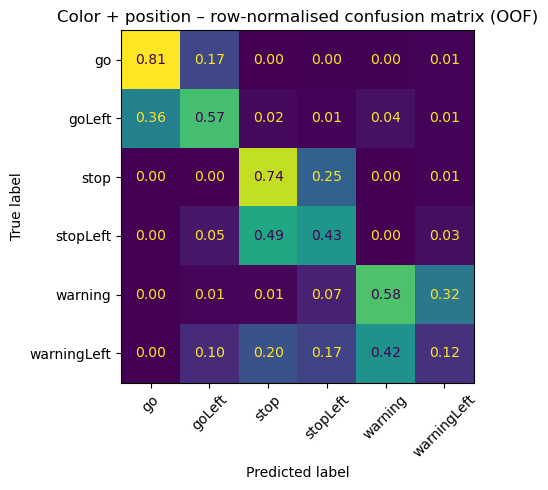

In [22]:
print(f"Pooled OOF macro-F1:        {f1_score(y, oof, labels=CLASSES, average='macro', zero_division=0):.3f}")
print(f"Pooled OOF balanced acc.:   {balanced_accuracy_score(y, oof):.3f}\n")
print(classification_report(y, oof, labels=CLASSES, zero_division=0, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y, oof, labels=CLASSES, normalize="true"),
                       display_labels=CLASSES).plot(ax=ax, values_format=".2f", colorbar=False)
ax.set_title("Color + position – row-normalised confusion matrix (OOF)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [23]:
def error_decomposition(y_true, y_pred):
    tc = np.array([COLOR_OF[t] for t in y_true]); pc = np.array([COLOR_OF[p] for p in y_pred])
    color_err = np.mean(tc != pc)                                # wrong colour
    shape_err = np.mean((tc == pc) & (y_true != y_pred))         # right colour, wrong arrow/circle
    stop_as_go = np.mean(pc[tc == "red"] == "green") if (tc == "red").any() else np.nan
    return {"6-class error": np.mean(y_true != y_pred), "color error": color_err,
            "shape error": shape_err, "3-class color acc.": 1 - color_err,
            "red -> green rate": stop_as_go}

res = {"all": error_decomposition(y, oof)}
for night in [False, True]:
    m = ann.isNight.to_numpy() == night
    if m.any():
        res["night" if night else "day"] = error_decomposition(y[m], oof[m])
pd.DataFrame(res).round(4)

,all,day,night
6-class error,0.2884,0.3424,0.1425
color error,0.0323,0.0422,0.0057
shape error,0.2561,0.3002,0.1368
3-class color acc.,0.9677,0.9578,0.9943
red -> green rate,0.0178,0.0208,0.0012


clip
dayTrain/dayClip9     77
dayTrain/dayClip10     2
dayTrain/dayClip8      2
Name: count, dtype: int64


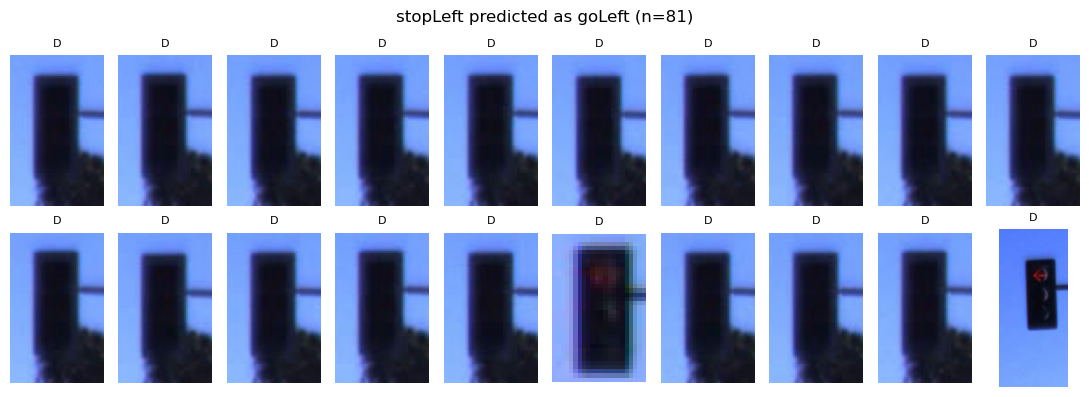

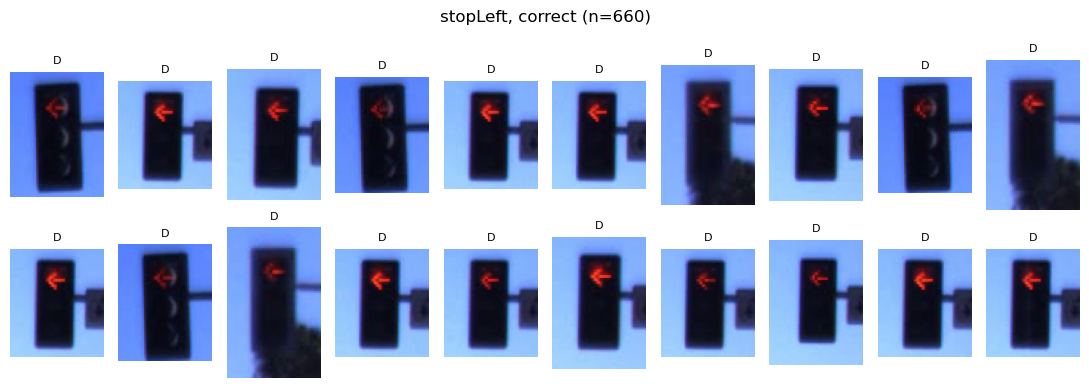

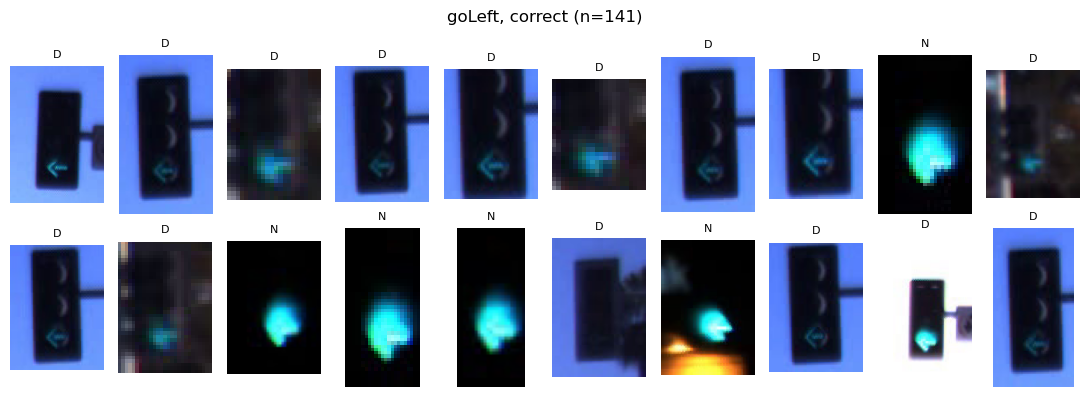

In [24]:
if "FRAME_PATH" not in globals():   # 加载了缓存时，图片索引还没建立
    FRAME_PATH = {os.path.basename(p): p for p in glob.glob(f"{ROOT}/**/frames/*.jpg", recursive=True)
                  if "sample-" not in p}

def crop(r, margin=0.15):
    img = cv2.cvtColor(cv2.imread(FRAME_PATH[r.frame]), cv2.COLOR_BGR2RGB)
    mx, my = int(r.w * margin), int(r.h * margin)
    H, W = img.shape[:2]
    return img[max(r.y1 - my, 0):min(r.y2 + my, H), max(r.x1 - mx, 0):min(r.x2 + mx, W)]

def show(df, title, n=20, cols=10):
    s = df.sample(min(n, len(df)), random_state=0)
    rows = (len(s) + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(cols * 1.1, rows * 2), squeeze=False)
    for a in ax.flat: a.axis("off")
    for a, r in zip(ax.flat, s.itertuples()):
        a.imshow(crop(r)); a.set_title("N" if r.isNight else "D", fontsize=8)
    fig.suptitle(f"{title} (n={len(df)})"); plt.tight_layout(); plt.show()

m = (y == "stopLeft") & (oof == "goLeft")
print(ann[m]["clip"].value_counts())
show(ann[m], "stopLeft predicted as goLeft")
show(ann[(y == "stopLeft") & (oof == "stopLeft")], "stopLeft, correct")
show(ann[(y == "goLeft") & (oof == "goLeft")], "goLeft, correct")

In [25]:
per_clip = pd.DataFrame({"clip": ann["clip"], "wrong": y != oof,
                         "red_as_green": (pd.Series(y).map(COLOR_OF) == "red").values
                                         & (pd.Series(oof).map(COLOR_OF) == "green").values})
print(per_clip.groupby("clip").agg(n=("wrong", "size"), error=("wrong", "mean"),
                                   red_as_green=("red_as_green", "sum")).round(3)
      .sort_values("error", ascending=False))

                          n  error  red_as_green
clip                                            
dayTrain/dayClip13      250  0.680             2
dayTrain/dayClip1      1599  0.529             0
dayTrain/dayClip10       29  0.517             4
dayTrain/dayClip2       437  0.455             0
dayTrain/dayClip6       227  0.370             0
dayTrain/dayClip9       390  0.354            78
dayTrain/dayClip5      1944  0.340             0
dayTrain/dayClip3       230  0.217             4
nightTrain/nightClip4   499  0.198             0
dayTrain/dayClip12       46  0.196             0
dayTrain/dayClip8       397  0.196             2
dayTrain/dayClip7      1620  0.189             0
nightTrain/nightClip5   651  0.151             0
nightTrain/nightClip3   405  0.146             0
nightTrain/nightClip2   901  0.128             1
dayTrain/dayClip11      255  0.118             2
nightTrain/nightClip1   352  0.082             0
dayTrain/dayClip4       160  0.075             0


In [26]:
tc, pc = pd.Series(y).map(COLOR_OF).values, pd.Series(oof).map(COLOR_OF).values
per_clip["color_err"] = tc != pc
per_clip["shape_err"] = (tc == pc) & (y != oof)
print(per_clip.groupby("clip")[["wrong", "color_err", "shape_err"]].mean().round(3)
      .sort_values("wrong", ascending=False))

                       wrong  color_err  shape_err
clip                                              
dayTrain/dayClip13     0.680      0.276      0.404
dayTrain/dayClip1      0.529      0.020      0.509
dayTrain/dayClip10     0.517      0.138      0.379
dayTrain/dayClip2      0.455      0.014      0.442
dayTrain/dayClip6      0.370      0.009      0.361
dayTrain/dayClip9      0.354      0.238      0.115
dayTrain/dayClip5      0.340      0.024      0.316
dayTrain/dayClip3      0.217      0.039      0.178
nightTrain/nightClip4  0.198      0.006      0.192
dayTrain/dayClip12     0.196      0.000      0.196
dayTrain/dayClip8      0.196      0.055      0.141
dayTrain/dayClip7      0.189      0.015      0.173
nightTrain/nightClip5  0.151      0.009      0.141
nightTrain/nightClip3  0.146      0.012      0.133
nightTrain/nightClip2  0.128      0.002      0.125
dayTrain/dayClip11     0.118      0.047      0.071
nightTrain/nightClip1  0.082      0.000      0.082
dayTrain/dayClip4      0.075   

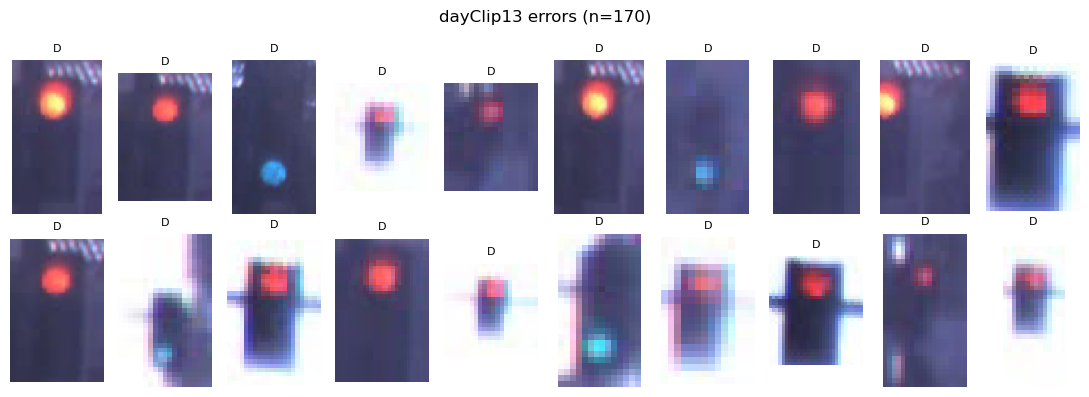

In [27]:
m = (ann["clip"] == "dayTrain/dayClip13").values & (y != oof)
show(ann[m], "dayClip13 errors")

## 5. How to read the results
- **Color error small, shape error large** → colour features already solve the colour part; the bottleneck is arrow vs. circle, so HOG (shape) features should give the biggest gain.
- **3-class colour accuracy near 100%** → confirms the 3-class task is nearly saturated and justifies the six-class focus.
- **Night clearly worse than day** → supports night-specific analysis and GMM class-conditionals.
- **Large spread across folds** → results depend strongly on which clips are held out; report mean ± std, not a single number.
- Record the pooled macro-F1 as *the number every later model must beat*.